# Check more audio before changing the method
Test the first 30 seconds of BOTH P1 and P2. Keep the previous 100 ms window,
20 ms hop, 60–1,000 Hz search, and 3x / 0.80 / 50-cent rule unchanged.
Preserve lesson 04's original results; write separate outputs tagged 0–30s.
This is a development check on more notes, not an untouched test set.

New diagnostic: `raw_RMS**2 = centered_RMS**2 + mean**2`.
Centered RMS measures variation around the window's average. A constant offset
contributes to raw RMS even though it is not oscillation. `mean**2/raw_RMS**2`
is the fraction of mean-square amplitude contributed by the window mean.
More than 50% means the mean contributes the majority: a REVIEW flag, not a
pitch filter or proof of noise. A trend may remain after subtracting the mean.
No detrending, high-pass filtering, peak-prominence rule or threshold tuning.


In [1]:
from pathlib import Path
import csv
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from pitch_analysis import estimate_period
from guitartechs_midi import read_note_labels

stop_seconds = 30.0
window_seconds = 0.100
hop_seconds = 0.020
minimum_frequency, maximum_frequency = 60.0, 1000.0
minimum_level_ratio, minimum_similarity, maximum_step_cents = 3.0, 0.80, 50.0
candidate_intervals = {"P1": (7.78, 7.90), "P2": (7.70, 7.86)}
output_folder = Path("outputs/pitch_tracking")
output_folder.mkdir(parents=True, exist_ok=True)
checks = {}


## 1. Measure every window, then apply the unchanged rule
The only new measurements are mean, centered RMS and mean-square fraction.
The acceptance rule STILL uses raw RMS and the same raw background reference.
MIDI is loaded after all audio decisions. Nothing is selected using note labels.
Adjacent windows share 80% of their samples; counts are not independent examples.


In [2]:
for player in ("P1", "P2"):
    folder = Path.home() / "Downloads" / f"{player}_singlenotes"
    audio_path = folder / "audio/directinput/directinput_allsinglenotes.wav"
    info = sf.info(audio_path)
    rate = info.samplerate
    stop_sample = round(stop_seconds * rate)
    if stop_sample > info.frames:
        raise ValueError("Requested excerpt exceeds this recording.")
    audio, rate = sf.read(audio_path, stop=stop_sample)
    signal = audio[:, 0] if audio.ndim == 2 else audio
    width, hop = round(window_seconds * rate), round(hop_seconds * rate)
    measurements = []
    for start in range(0, len(signal) - width + 1, hop):
        window = signal[start:start + width]
        frequency, lag, score = estimate_period(window, rate, minimum_frequency, maximum_frequency)
        mean = float(np.mean(window))
        raw_rms = float(np.sqrt(np.mean(window ** 2)))
        centered_rms = float(np.sqrt(np.mean((window - mean) ** 2)))
        mean_fraction = mean ** 2 / raw_rms ** 2 if raw_rms > 0 else 0.0
        assert np.isclose(raw_rms ** 2, centered_rms ** 2 + mean ** 2, rtol=1e-10, atol=1e-20)
        measurements.append(dict(player=player, source_file=audio_path.name, sample_rate=rate,
            start_sample=start, stop_sample_exclusive=start + width,
            midpoint_seconds=(start + width / 2) / rate,
            candidate_hz=frequency, lag_samples=lag, similarity=score,
            rms=raw_rms, mean=mean, centered_rms=centered_rms, mean_square_fraction=mean_fraction))

    background_start, background_stop = [round(t * rate) for t in candidate_intervals[player]]
    background = [row for row in measurements if row['start_sample'] >= background_start
                  and row['stop_sample_exclusive'] <= background_stop]
    if not background:
        raise ValueError("No complete windows inside candidate background interval.")
    reference = float(np.median([row['rms'] for row in background]))
    if reference <= 0:
        raise ValueError("Background reference must be positive.")
    previous_eligible, previous_hz = False, np.nan
    for row in measurements:
        hz = row['candidate_hz']
        finite_pitch = bool(np.isfinite(hz) and hz > 0)
        ratio = row['rms'] / reference
        level_ok = bool(ratio >= minimum_level_ratio)
        repetition_ok = bool(np.isfinite(row['similarity']) and row['similarity'] >= minimum_similarity)
        eligible = finite_pitch and level_ok and repetition_ok
        step = abs(1200 * np.log2(hz / previous_hz)) if finite_pitch and np.isfinite(previous_hz) and previous_hz > 0 else np.nan
        continuity_ok = bool(previous_eligible and np.isfinite(step) and step <= maximum_step_cents)
        passes = bool(eligible and continuity_ok)
        row.update(reference_rms=reference, background_start_sample=background_start,
                   background_stop_sample_exclusive=background_stop,
                   minimum_level_ratio=minimum_level_ratio, minimum_similarity=minimum_similarity,
                   maximum_step_cents=maximum_step_cents, level_ratio=ratio,
                   level_ok=level_ok, repetition_ok=repetition_ok, continuity_ok=continuity_ok,
                   step_cents=step, accepted=passes, accepted_hz=hz if passes else np.nan,
                   review_mean_dominates=bool(row['mean_square_fraction'] > 0.5))
        previous_eligible, previous_hz = eligible, hz

    # Check the same rule reproduces all saved 11.9-second decisions if present.
    previous_path = output_folder / f"{player}_singlenotes_pitch_decisions.csv"
    if previous_path.exists():
        with previous_path.open() as handle:
            previous_rows = list(csv.DictReader(handle))
        assert len(previous_rows) <= len(measurements)
        for before, now in zip(previous_rows, measurements):
            assert int(before['start_sample']) == now['start_sample']
            for key in ('candidate_hz', 'similarity', 'rms', 'reference_rms'):
                assert np.isclose(float(before[key]), now[key], equal_nan=True)
            assert (before['accepted'] == 'True') == now['accepted']
        print(f"{player}: original {len(previous_rows)} rows reproduced without changes.")
    labels, _ = read_note_labels(folder / "midi/midi_allsinglenotes.mid")
    labels = [note for note in labels if note['start_seconds'] < stop_seconds]
    checks[player] = dict(rows=measurements, labels=labels, reference=reference)
    print(f"{player}: {len(measurements)} windows; {sum(row['accepted'] for row in measurements)} pass. Not accuracy.")


P1: original 591 rows reproduced without changes.
P1: 1496 windows; 1247 pass. Not accuracy.
P2: original 591 rows reproduced without changes.
P2: 1496 windows; 1311 pass. Not accuracy.


## 2. Compare raw and centered level across the whole excerpt
Orange: all candidates; green: pass the old rule; red rings: pass AND have
more than half their mean-square amplitude from their window mean.
Red does NOT mean a proven false pitch. Blue lines are nominal MIDI references.
Both RMS curves use the SAME original raw reference as denominator: this plot
isolates the effect of centering, not a recalibrated alternative detector.
Dashed vertical lines mark 11.9 s: everything to the right is newly inspected.


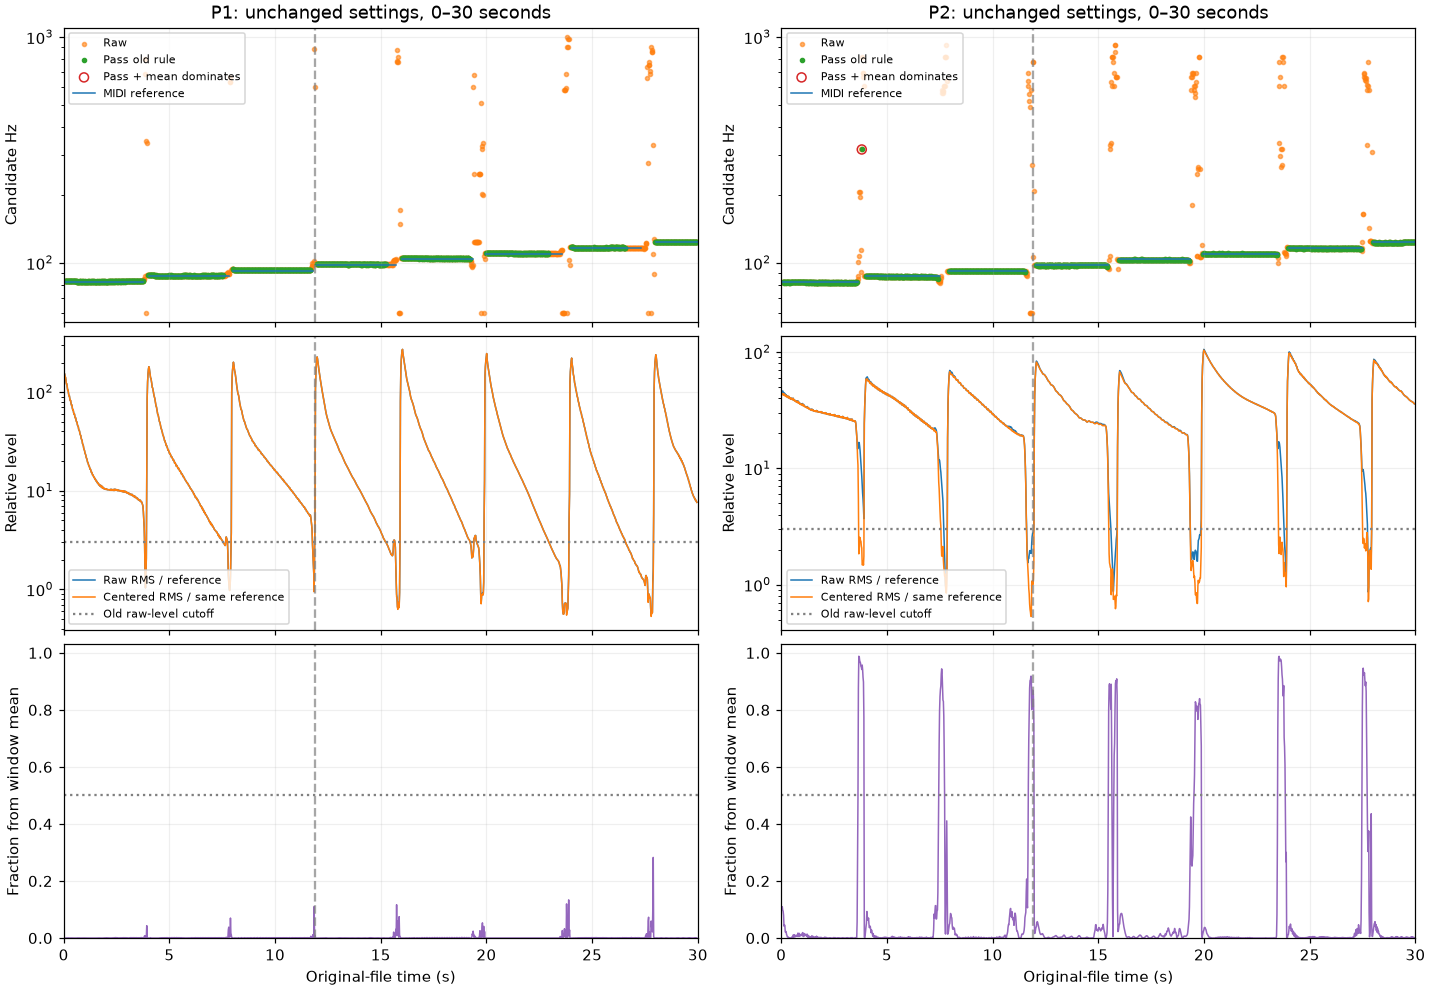

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex=True, constrained_layout=True)
for column, (player, result) in enumerate(checks.items()):
    rows = result['rows']
    time = np.array([row['midpoint_seconds'] for row in rows])
    frequency = np.array([row['candidate_hz'] for row in rows])
    passes = np.array([row['accepted'] for row in rows])
    fraction = np.array([row['mean_square_fraction'] for row in rows])
    flagged = passes & (fraction > 0.5)
    axes[0, column].scatter(time, frequency, s=7, color='tab:orange', alpha=0.6, label='Raw')
    axes[0, column].scatter(time[passes], frequency[passes], s=7, color='tab:green', label='Pass old rule')
    axes[0, column].scatter(time[flagged], frequency[flagged], s=35, facecolors='none', edgecolors='tab:red', label='Pass + mean dominates')
    for i, note in enumerate(result['labels']):
        hz = 440 * 2 ** ((note['midi_note'] - 69) / 12)
        axes[0, column].plot([note['start_seconds'], min(note['end_seconds'], stop_seconds)], [hz, hz],
                            color='tab:blue', linewidth=1, label='MIDI reference' if i == 0 else None)
    axes[0, column].set(title=f'{player}: unchanged settings, 0–30 seconds', yscale='log',
                        ylim=(55, 1100), ylabel='Candidate Hz')
    axes[0, column].legend(fontsize=7, loc='upper left')
    axes[1, column].plot(time, [row['level_ratio'] for row in rows], label='Raw RMS / reference', linewidth=1)
    axes[1, column].plot(time, [row['centered_rms'] / result['reference'] for row in rows],
                        label='Centered RMS / same reference', linewidth=1)
    axes[1, column].axhline(minimum_level_ratio, color='0.5', linestyle=':', label='Old raw-level cutoff')
    axes[1, column].set(yscale='log', ylabel='Relative level')
    axes[1, column].legend(fontsize=7)
    axes[2, column].plot(time, fraction, color='tab:purple', linewidth=1)
    axes[2, column].axhline(0.5, color='0.5', linestyle=':', label='Majority of mean-square amplitude')
    axes[2, column].set(ylabel='Fraction from window mean', xlabel='Original-file time (s)', ylim=(0, 1.03))
    for ax in axes[:, column]:
        ax.axvline(11.9, color='0.5', linestyle='--', alpha=0.7)
        ax.set_xlim(0, stop_seconds)
        ax.grid(alpha=0.2)
fig.savefig(output_folder / 'P1_P2_0-30s_offset_check.png', dpi=150)
plt.show()


## 3. Summarize review regions, not a fake accuracy percentage
Group consecutive flagged windows into review runs to avoid listing overlapping
windows as separate discoveries. These are not detected note events.
Also inspect windows wholly inside MIDI note spans with a 100 ms guard at each
end. This deliberately leaves uncertain boundaries out of that comparison;
it is not whole-recording accuracy, nor proof of silence outside the labels.
A 50-cent discrepancy is an inspection convention, not a new rejection rule.


In [4]:
for player, result in checks.items():
    rows = result['rows']
    all_flagged = sum(row['review_mean_dominates'] for row in rows)
    new_all_flagged = sum(row['review_mean_dominates'] and row['midpoint_seconds'] > 11.9 for row in rows)
    print(f"\n{player}: {all_flagged} windows have majority mean-square contribution from their mean; "
          f"{new_all_flagged} are after 11.9 s (overlapping, not independent).")
    print("Passing windows among those:")
    runs = []
    for index, row in enumerate(rows):
        if row['accepted'] and row['review_mean_dominates']:
            if runs and index == runs[-1][-1] + 1:
                runs[-1].append(index)
            else:
                runs.append([index])
    for run in runs:
        first, last = rows[run[0]], rows[run[-1]]
        print(f"  midpoints {first['midpoint_seconds']:.2f}–{last['midpoint_seconds']:.2f}s: "
              f"{len(run)} overlapping windows; "
              f"Hz {min(rows[i]['candidate_hz'] for i in run):.2f}–{max(rows[i]['candidate_hz'] for i in run):.2f}; "
              f"mean fraction {min(rows[i]['mean_square_fraction'] for i in run):.2f}–{max(rows[i]['mean_square_fraction'] for i in run):.2f}")
    new_flagged = sum(row['accepted'] and row['review_mean_dominates'] and row['midpoint_seconds'] > 11.9 for row in rows)
    print(f"  Newly inspected portion: {new_flagged} flagged passing windows (not independent).")
    for note in result['labels']:
        interior = [row for row in rows if row['start_sample'] / row['sample_rate'] >= note['start_seconds'] + 0.1
                    and row['stop_sample_exclusive'] / row['sample_rate'] <= note['end_seconds'] - 0.1]
        if not interior:
            continue
        target = 440 * 2 ** ((note['midi_note'] - 69) / 12)
        passing = [row for row in interior if row['accepted']]
        discrepancies = [row for row in passing if abs(1200 * np.log2(row['candidate_hz'] / target)) > 50]
        print(f"  MIDI {note['midi_note']} ({target:.2f} Hz): {len(passing)}/{len(interior)} interior windows pass; "
              f"{len(discrepancies)} passing estimates differ >50 cents.")
    path = output_folder / f'{player}_singlenotes_0-30s_offset_check.csv'
    with path.open('w', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    print('Saved:', path)



P1: 0 windows have majority mean-square contribution from their mean; 0 are after 11.9 s (overlapping, not independent).
Passing windows among those:
  Newly inspected portion: 0 flagged passing windows (not independent).
  MIDI 40 (82.41 Hz): 172/172 interior windows pass; 0 passing estimates differ >50 cents.
  MIDI 41 (87.31 Hz): 168/174 interior windows pass; 0 passing estimates differ >50 cents.
  MIDI 42 (92.50 Hz): 173/173 interior windows pass; 0 passing estimates differ >50 cents.
  MIDI 43 (98.00 Hz): 155/172 interior windows pass; 0 passing estimates differ >50 cents.
  MIDI 44 (103.83 Hz): 152/152 interior windows pass; 0 passing estimates differ >50 cents.
  MIDI 45 (110.00 Hz): 140/165 interior windows pass; 0 passing estimates differ >50 cents.
  MIDI 46 (116.54 Hz): 121/151 interior windows pass; 0 passing estimates differ >50 cents.
  MIDI 47 (123.47 Hz): 90/90 interior windows pass; 0 passing estimates differ >50 cents.
Saved: outputs/pitch_tracking/P1_singlenotes_0-

## What we found with settings fixed (2026-11-03)
Each player has 1,496 windows across eight MIDI note spans (the last is partial).
P1: 1,247 windows pass; P2: 1,311. These counts are not accuracy percentages.

P2's mean-dominated windows DO recur: 106 total, including 67 after 11.9 s.
But the existing rule rejects all 67 newly inspected ones. Only the previously
inspected 3.81 s window passes with a majority mean contribution. P1 has no
windows meeting this diagnostic condition. So the offset pattern is not unique
to one instant, but we did not find another passing instance of that pattern.
This flag doesn't detect every possible wrong pitch or establish physical cause.

Within guarded MIDI interiors, P1 passes 1,171 of 1,249 windows and P2 passes
all 1,207. Every passing interior estimate is within 50 cents of its reference.
P1 rejects 78 interior windows: missed coverage matters alongside pitch error.
We intentionally exclude boundaries from that check; uncertain label timing,
tuning, and overlapping samples mean these are not independent accuracy trials.

Verdict: keep the current settings for now. Do not add an exception for 318 Hz
or switch to centered RMS based on one accepted example. Next inspect a few
rejected P1 ringing windows, then work toward grouping reliable windows into
note events. Faster picking/chords and more strings remain untested here.
